# Filtry konwolucyjne
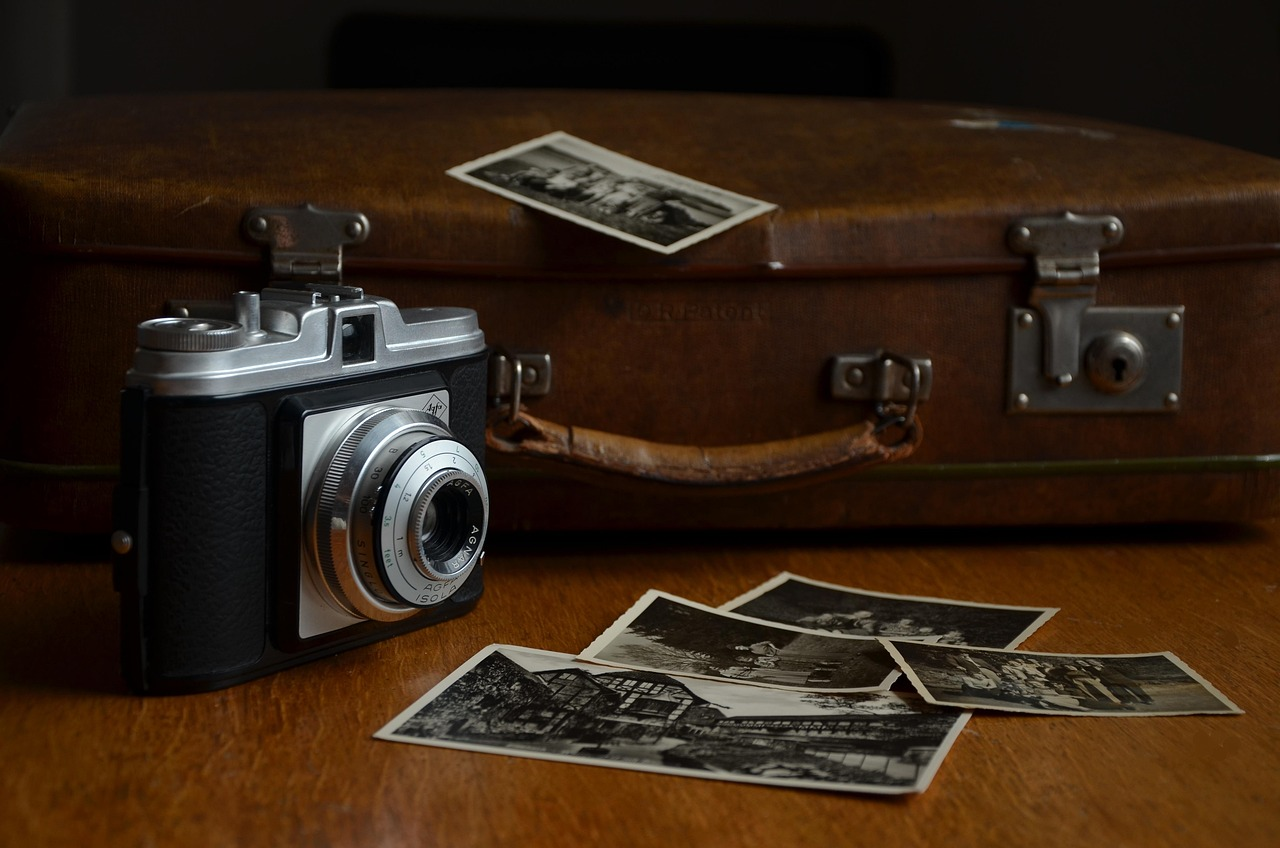

*Źródło: Pixabay*

## Wstęp
Wyobraź sobie, że znajdujesz na strychu stare, rodzinne fotografie. Niestety, upływ czasu sprawił, że zdjęcia są wyblakłe, zaszumione i nieostre. Chcesz je odrestaurować i przywrócić im dawną świetność. Możesz spędzić wiele godzin, ręcznie poprawiając je w programie graficznym, ale co, gdyby dało się stworzyć jeden, uniwersalny "magiczny filtr", który automatycznie naprawi każde zepsute zdjęcie?

W tym zadaniu Twoim celem jest właśnie stworzenie takiego "przepisu" na naprawę obrazów. Ten przepis, w świecie informatyki i sztucznej inteligencji, nazywa się **kernelem konwolucji**. To fundamentalne narzędzie w przetwarzaniu obrazów, które leży u podstaw tego, jak komputery "widzą" i rozumieją świat.

## Czym jest Konwolucja?

Zanim przejdziemy do zadania, musimy zrozumieć dwie rzeczy: czym jest obraz dla komputera i jak działa na nim "magiczny filtr", czyli konwolucja.

### Czym jest obraz dla komputera?
Dla nas obraz to twarz, krajobraz, czy kot. Dla komputera to po prostu **wielka siatka z liczbami**. Każda liczba w tej siatce odpowiada jasności jednego **piksela**. W obrazach kolorowych mamy trzy takie siatki – jedną dla koloru czerwonego (R), jedną dla zielonego (G) i jedną dla niebieskiego (B).

### Jak działa konwolucja?
Konwolucja to operacja, w której niewielka macierz liczb (np. o rozmiarze 3x3), zwana **kernelem**, jest przesuwana po całym obrazie, piksel po pikselu.

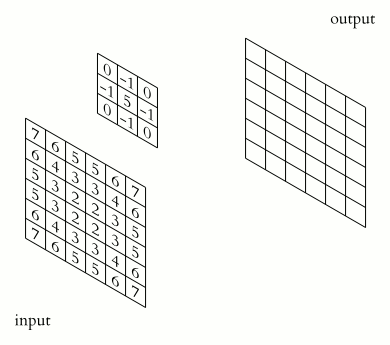

*Źródło: Michael Plotke, CC BY-SA 3.0 <https://creativecommons.org/licenses/by-sa/3.0>, via Wikimedia Commons*

Dla każdego położenia kernela na obrazie, wykonujemy prostą operację:
1.  Bierzemy fragment obrazu znajdujący się pod kernelem i **mnożymy** odpowiadające sobie wartości pikseli i wag z kernela.
2.  **Sumujemy** wszystkie te wyniki.
3.  Wynik tej sumy staje się **nową wartością piksela** w nowym, przetworzonym obrazie.

W zależności od tego, jakie liczby wpiszemy do kernela, uzyskamy zupełnie inne efekty.

## Przykłady kerneli

| Kernel (Macierz 3x3) | Efekt na obrazie |
|:---:|:---:|
| **Identyczność**<br>Jedynka w środku sprawia, że nowy piksel jest idealną kopią oryginalnego.<br> $$\begin{bmatrix} 0 & 0 & 0 \\ 0 & 1 & 0 \\ 0 & 0 & 0 \end{bmatrix}$$ | 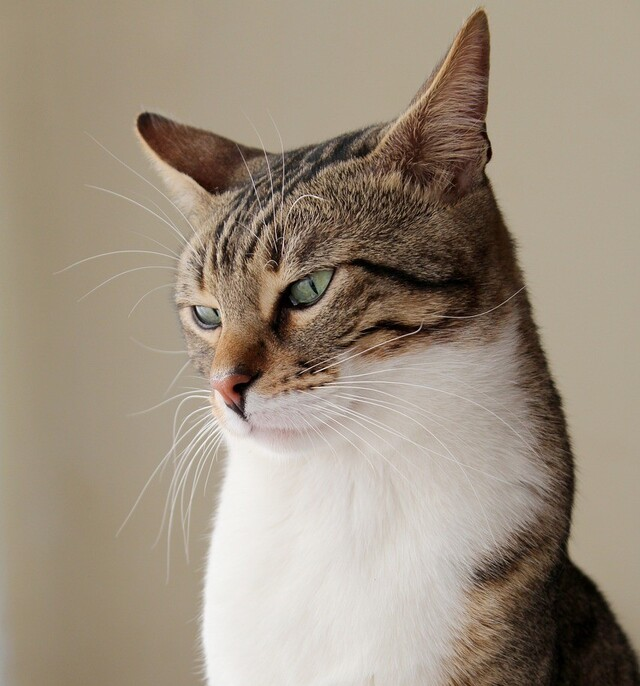 |
| **Rozmycie**<br>Uśrednia wartość piksela z jego sąsiadami, co wygładza obraz.<br> $$\begin{bmatrix} \frac{1}{9} & \frac{1}{9} & \frac{1}{9} \\ \frac{1}{9} & \frac{1}{9} & \frac{1}{9} \\ \frac{1}{9} & \frac{1}{9} & \frac{1}{9} \end{bmatrix}$$ | 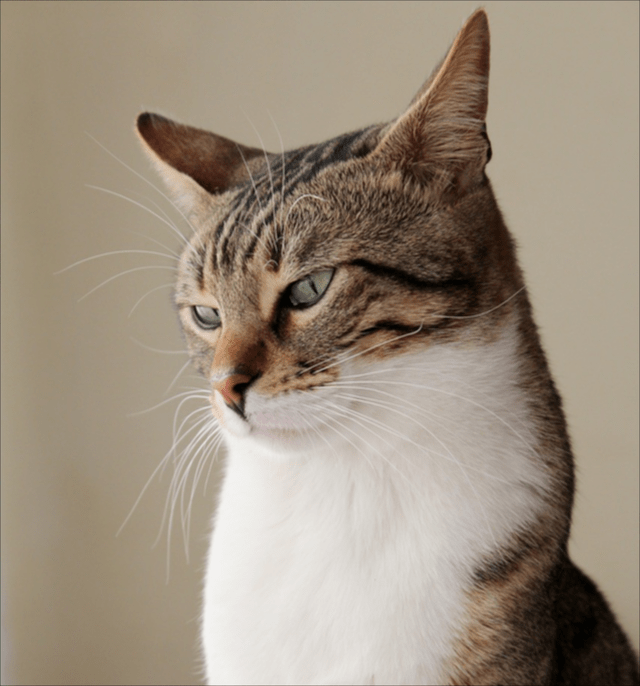 |
| **Wyostrzanie**<br>Podkreśla różnice między pikselem a jego otoczeniem, uwydatniając detale.<br> $$\begin{bmatrix} 0 & -1 & 0 \\ -1 & 5 & -1 \\ 0 & -1 & 0 \end{bmatrix}$$ | 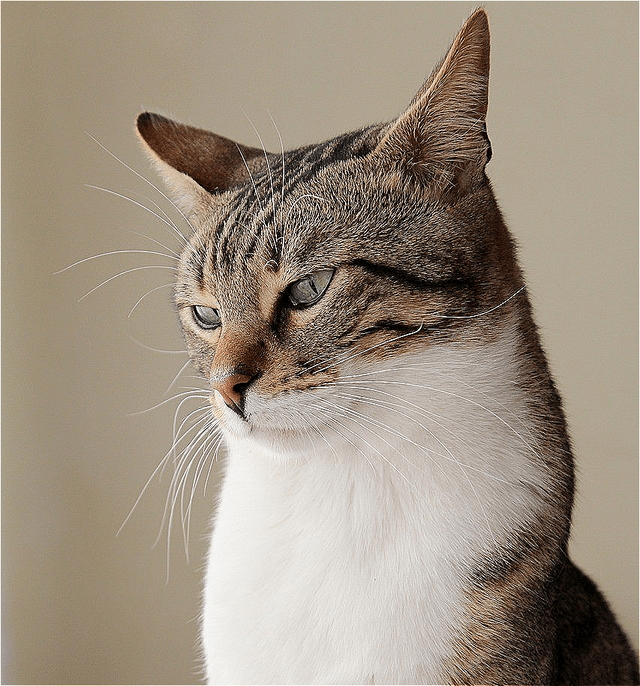 |
| **Wykrywanie krawędzi pionowych**<br>Wzmacnia miejsca, gdzie po lewej stronie są ciemne piksele, a po prawej jasne.<br> $$\begin{bmatrix} -1 & 0 & 1 \\ -2 & 0 & 2 \\ -1 & 0 & 1 \end{bmatrix}$$ | 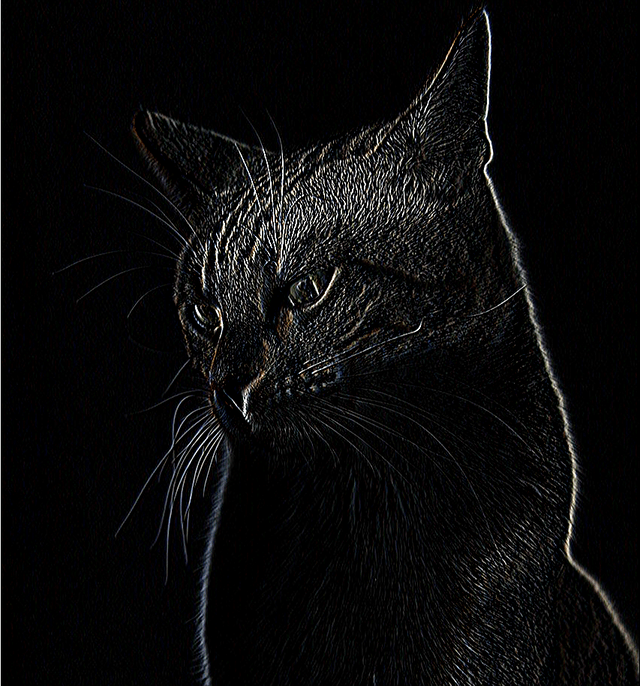 |


## A czym jest upsampling?

W drugiej części zadania spotkasz się z pojęciem **upsamplingu**, czyli **powiększania obrazu**.
To operacja odwrotna do zmniejszania (downsamplingu):
mamy mały obraz, np. 128x128 pikseli, i chcemy z niego uzyskać większy — np. 256x256.

Problem w tym, że komputer nie wie, jakie powinny być wartości nowych, „wymyślonych” pikseli.
Dlatego musi je jakoś **zgadnąć**.

Najprostszy sposób to wymyślić bardzo prostą regułę, na przykład taką (nazywaną **nearest neighbor upsampling**):

> Każdy piksel z małego obrazu po prostu **powielamy** w poziomie i pionie tyle razy, ile potrzeba, aby wypełnić większy blok pikseli.

W efekcie powiększony obraz wygląda jak powiększona „mozaika” — kształty są zachowane, ale widać wyraźnie ostre krawędzie i duże piksele.

## Zadanie

W tym zadaniu będziesz pracować nad dwiema powiązanymi częściami:

1.   Część pierwsza — Kernel konwolucyjny
2.   Część druga — Upsampling (powiększanie obrazów)

Każda z nich jest oceniana niezależnie.

### Część 1 — Kernel konwolucyjny

Twoim zadaniem jest znalezienie **jednego, uniwersalnego kernela (filtru)**,
który potrafi przywracać zepsute zdjęcia do formy jak najbardziej zbliżonej do oryginałów.

*Uwaga:* Rozmiar kernela nie powinien przekroczyć **10x10**.

Jako punkt wyjścia otrzymujesz funkcję `compute_kernel()`,
która zwraca prosty filtr — tzw. **kernel rozmywający** 9x9 (wyżej znajdziesz przykład pokazujący działanie takiego kernela w rozmiarze 3x3).

Zamiast ręcznego dobierania wag, możesz wykorzystać mechanizm `autograd` z biblioteki PyTorch. Służy on do automatycznej optymalizacji – w iteracyjnym procesie dopasuje wartości w kernelu tak, aby błąd rekonstrukcji obrazu był jak najmniejszy.

### Część 2 — Upsampling

W drugiej części skupisz się na problemie powiększania obrazów.

Tym razem Twoim zadaniem jest zaimplementowanie funkcji `upsample(image: torch.Tensor) -> torch.Tensor`,
która otrzymuje pomniejszony obraz (`(C, h, w)`) i ma go powiększyć do pełnego rozmiaru (`(C, H, W)`).

Punktem odniesienia (bazą) będzie bardzo prosta metoda,
**nearest neighbor**, która powiela każdy piksel odpowiednią liczbę razy w pionie i poziomie.

Oprócz funkcji `upsample` masz również możliwość dobrania **dodatkowego kernela** (wyliczanego przez funkcję `compute_kernel_upsampling(kernel_task1: torch.Tensor) -> torch.Tensor`), który zostanie zastosowany *po* upsamplingu, już na powiększonym obrazie. Domyślnie jest to kernel z pierwszej części zadania.

W tej części oceniana jest jakość rekonstrukcji obrazu po dwóch etapach:

1. **upsampling (funkcja `upsample()`)**,
2. **konwolucja z Twoim kernelem (funkcja `compute_kernel_upsampling(...)`)**.

## Dane

W tym zadaniu dostępne są dla Ciebie dwa zbiory danych zapisane w jednym pliku (`train_val.npz`):

*   `train_ds` — **150 przykładów treningowych**,
*   `val_ds` — **50 przykładów walidacyjnych**.

Każdy przykład to **trójka powiązanych obrazów**:


*   `image_original` – oryginalny, poprawny obraz w rozdzielczości **256x256 pikseli**,
*   `image_corrupted` – ten sam obraz po zniekształceniu, również **256x256**,
*   `image_corrupted_downsampled` – wersja `image_corrupted` pomniejszona do **128x128**,
na której będziesz testować swoje metody upsamplingu.

Wszystkie obrazy są kolorowe (RGB) i zapisane w formacie **tensorów PyTorch** o kształcie `(3, H, W)`
oraz wartościach znormalizowanych do zakresu **[0, 1]**.

## Kryterium Oceny
Obie części zadania zostaną ocenione na podstawie metryki **MSE (Mean Squared Error)**, czyli Błędu Średniokwadratowego. Jest to prosty sposób na zmierzenie, jak bardzo różnią się od siebie dwa obrazki. Metryka ta liczy różnicę między każdym pikselem w obrazie zrekonstruowanym a oryginalnym, podnosi te różnice do kwadratu i wyciąga z nich średnią.

**Im niższa wartość MSE, tym obrazki są do siebie bardziej podobne, a Twoje rozwiązanie jest lepsze.**

### Część 1 (70 pkt.) - Kernel konwolucyjny
- Za tę część możesz zdobyć maksymalnie 70 punktów.
- Gdy wartość MSE dla Twojego rozwiązania będzie wynosiła 0.0285 (lub więcej), otrzymasz 0 punktów za tę część zadania.
- Gdy wartość MSE dla Twojego rozwiązania będzie wynosiła 0.0077 (lub mniej), otrzymasz 70 punktów za tę część zadania.
- W przeciwnym wypadku, liczba punktów zostanie wyznaczona proporcjonalnie do wartości MSE:
$$
\text{score} \_ \text{kernel} = round(\frac{0.0285 - \text{MSE} \_ \text{kernel}}{0.0285 - 0.0077} \times 70)
$$

### Część 2 (30 pkt.) - Upsampling
- Za tę część możesz zdobyć maksymalnie 30 punktów.
- Gdy wartość MSE dla Twojego rozwiązania będzie wynosiła 0.0542 (lub więcej), otrzymasz 0 punktów za tę część zadania.
- Gdy wartość MSE dla Twojego rozwiązania będzie wynosiła 0.0350 (lub mniej), otrzymasz 30 punktów za tę część zadania.
- W przeciwnym wypadku, liczba punktów zostanie wyznaczona proporcjonalnie do wartości MSE:
$$
\text{score} \_ \text{upsampling} = round(\frac{0.0542 - \text{MSE} \_ \text{upsampling}}{0.0542 - 0.0350} \times 30)
$$

### Wynik końcowy

Końcowa punktacja to suma wyników z obu części:
$$
\text{Wynik końcowy} = \text{score} \_ \text{kernel} + \text{score} \_ \text{upsampling}
$$
czyli:
- **70% punktów** pochodzi z jakości Twojego kernela (funkcji `compute_kernel()`)
- **30% punktów** z jakości Twoich funkcji `upsample()` i `compute_kernel_upsampling()`.

## Ograniczenia
- Twoje rozwiązanie będzie testowane na Platformie Konkursowej bez dostępu do internetu oraz w środowisku z GPU.
- Ewaluacja Twojego finalnego rozwiązania na Platformie Konkursowej nie może trwać dłużej niż 3,5 minuty z GPU.
- Dozwolone biblioteki: `numpy`, `torch` (w rozwiązaniu **nie można** używać modułu `torch.nn`).

## Pliki Zgłoszeniowe
Ten notebook uzupełniony o Twoje rozwiązanie (funkcje `compute_kernel`, `compute_kernel_upsampling` i `upsample`).

## Ewaluacja
Pamiętaj, że podczas sprawdzania flaga `FINAL_EVALUATION_MODE` zostanie ustawiona na `True`.

Za to zadanie możesz zdobyć pomiędzy 0 a 100 punktów. Liczba punktów, którą zdobędziesz, będzie wyliczona na (tajnym) zbiorze testowym na Platformie Konkursowej na podstawie wyżej wspomnianego wzoru, zaokrąglona do liczby całkowitej. Jeśli Twoje rozwiązanie nie będzie spełniało powyższych kryteriów lub nie będzie wykonywać się prawidłowo, otrzymasz za zadanie 0 punktów.

## Kod Startowy
W tej sekcji inicjalizujemy środowisko poprzez zaimportowanie potrzebnych bibliotek i funkcji. Przygotowany kod ułatwi Tobie efektywne operowanie na danych i budowanie właściwego rozwiązania.

In [ ]:
######################### NIE ZMIENIAJ TEJ KOMÓRKI ##########################

FINAL_EVALUATION_MODE = False  # Podczas sprawdzania ustawimy tę flagę na True.

In [ ]:
######################### NIE ZMIENIAJ TEJ KOMÓRKI ##########################

if not FINAL_EVALUATION_MODE:
    import matplotlib.pyplot as plt

import os
import torch
import numpy as np
import math
import shutil
from typing import Callable, Optional

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
######################### NIE ZMIENIAJ TEJ KOMÓRKI ##########################

seed = 12345

os.environ["PYTHONHASHSEED"] = str(seed)
torch.manual_seed(seed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [ ]:
######################### NIE ZMIENIAJ TEJ KOMÓRKI ##########################
# Komórka zawierająca funkcje pomocnicze do przygotowania danych.

def download_data() -> None:
    """Pobiera zbiór danych z Google Drive i zapisuje go w folderze 'data'."""
    import gdown

    # Utwórz lub zresetuj folder 'data'
    if not os.path.exists('data'):
        os.makedirs('data')
    else:
        shutil.rmtree('data')
        os.makedirs('data')

    # Pobierz plik z Google Drive i zapisz go w folderze 'data'
    url = "https://drive.google.com/file/d/1wzYqBQ56IMXpM7_gv05vzercvZSZy-Ps/view?usp=drive_link"
    output = f'data/train_val.npz'
    gdown.download(url, output, quiet=True,fuzzy=True)

def setup_data_from_npz(npz_path: str) -> tuple[list[dict], list[dict]]:
    """
    Ładuje trójki obrazów (oryginalne, zepsute i zmniejszone (downsampled)
    zepsute) z pliku NPZ i zwraca je w postaci dwóch list słowników.

    Przyjmuje:
        npz_path (str): Ścieżka do pliku .npz z danymi.

    Zwraca:
        tuple[list[dict], list[dict]]:
            - train_ds: lista słowników {'image_original': tensor,
                'image_corrupted': tensor, 'image_corrupted_downsampled': tensor}
            - val_ds:   lista słowników w tym samym formacie, ale dla walidacji.
    """
    # Ładowanie danych z pliku
    data = np.load(npz_path, allow_pickle=True)
    train_list = data['train_ds'].tolist()
    val_list   = data['val_ds'].tolist()

    def to_tensor_triplet(sample: dict) -> dict:
        # Konwertujemy wczytane dane (uint8) na float32
        # i skalujemy je z powrotem do zakresu [0, 1] dzieląc przez 255.0
        return {
            "image_original": torch.from_numpy(sample["image_original"]).to(torch.float32) / 255.0,
            "image_corrupted": torch.from_numpy(sample["image_corrupted"]).to(torch.float32) / 255.0,
            "image_corrupted_downsampled": torch.from_numpy(sample["image_corrupted_downsampled"]).to(torch.float32) / 255.0,
        }

    train_ds = [to_tensor_triplet(s) for s in train_list]
    val_ds   = [to_tensor_triplet(s) for s in val_list]

    return train_ds, val_ds

In [ ]:
######################### NIE ZMIENIAJ TEJ KOMÓRKI ##########################
# Komórka zawierająca funkcje pomocnicze do ewaluacji rozwiązania.

def _pad_replicate(x: torch.Tensor, pad: int) -> torch.Tensor:
    """
    „Dopełnienie przez powielanie” — dodaje ramkę z pikseli brzegowych obrazu.
    Przydaje się do operacji konwolucji (kernel w środku, brzeg nie „ucieka”).

    Przyjmuje:
        x (torch.Tensor): Obraz o kształcie (C, H, W).
        pad (int): Liczba pikseli do dodania po każdej stronie.

    Zwraca:
        torch.Tensor: Obraz o powiększonym rozmiarze (C, H+2*pad, W+2*pad).
    """
    if pad == 0:
        return x
    # Dopełnienie w pionie: duplikujemy pierwszy i ostatni wiersz.
    top    = x[:, :1, :].expand(-1, pad, -1)
    bottom = x[:, -1:, :].expand(-1, pad, -1)
    xvb = torch.cat([top, x, bottom], dim=1)          # (C, H+2p, W)
    # Dopełnienie w poziomie: duplikujemy pierwszą i ostatnią kolumnę.
    left  = xvb[:, :, :1].expand(-1, -1, pad)
    right = xvb[:, :, -1:].expand(-1, -1, pad)
    xpad = torch.cat([left, xvb, right], dim=2)       # (C, H+2p, W+2p)
    return xpad

def apply_kernel(image: torch.Tensor, kernel: torch.Tensor) -> torch.Tensor:
    """
    Zastosowanie tego samego filtra (kernela) do każdej składowej kanałowej obrazu.

    Przyjmuje:
        image (torch.Tensor): Obraz o kształcie (C, H, W) w zakresie [0,1].
        kernel (torch.Tensor): Filtr 2D o kształcie (K, K).

    Zwraca:
        torch.Tensor: Nowy obraz (C, H, W) po zastosowaniu kernela.
    """
    assert image.dim() == 3, "image musi mieć wymiary (C,H,W)"
    assert kernel.dim() == 2 and kernel.size(0) == kernel.size(1), "kernel musi być kwadratem (K,K)"
    assert kernel.size(0) <= 10, "rozmiar kernela nie może przekraczać 10x10"
    C, H, W = image.shape
    K = kernel.size(0)
    pad = K // 2

    # Dopełnienie replikacją (bez modyfikacji w miejscu — ważne dla autograd).
    xpad = _pad_replicate(image, pad)                 # (C, H+2p, W+2p)

    # Tworzymy „okienka” z sąsiednich pikseli dla każdego miejsca w obrazie: (C, H, W, K, K)
    sC, sH, sW = xpad.stride()
    windows = xpad.as_strided(
        size=(C, H, W, K, K),
        stride=(sC, sH, sW, sH, sW)
    )

    # Obliczamy korelację: mnożenie element po elemencie i sumowanie po sąsiedztwie KxK
    out = (windows * kernel.view(1, 1, 1, K, K)).sum(dim=(-1, -2))   # (C,H,W)
    return out

def evaluate_solution(
    kernel: torch.Tensor,
    ds: list[dict],
    upsample_fun: Optional[Callable] = None
) -> float:
    """
    Oblicza średni błąd MSE (Mean Squared Error) na podanym zbiorze danych.

    Przyjmuje:
        kernel (torch.Tensor): Filtr 2D (np. 5x5), który ma zostać oceniony.
        ds (list[dict]): Lista próbek z kluczami 'image_original',
            'image_corrupted' i 'image_corrupted_downsampled'.
        upsample_fun (Optional[Callable]): (Opcjonalnie) Funkcja do upsamplingu
            (torch.Tensor -> torch.Tensor), która ma zostać oceniona.

    Zwraca:
        float: Średnia wartość błędu MSE dla całego zbioru.
    """
    total_mse = 0.0
    kernel = kernel.to(DEVICE)

    # Nie potrzebujemy gradientów podczas ewaluacji — przyspiesza i oszczędza pamięć.
    with torch.no_grad():
        for sample in ds:
            original = sample['image_original'].to(DEVICE)

            # Wybór właściwej wersji "corrupted":
            # - jeśli podano funkcję upsamplingu, powiększamy wersję zmniejszoną,
            # - w przeciwnym razie bierzemy wersję w pełnym rozmiarze.
            if upsample_fun is not None:
                corrupted = sample['image_corrupted_downsampled'].to(DEVICE)
                corrupted = upsample_fun(corrupted)  # oczekujemy (C, H, W)
            else:
                corrupted = sample['image_corrupted'].to(DEVICE)  # już (C, H, W)

            # Rekonstrukcja obrazu przez zastosowanie kernela do „zepsutego” obrazu.
            reconstructed = apply_kernel(corrupted, kernel)
            # MSE: średnia z kwadratów różnic piksel po pikselu.
            mse = torch.mean((reconstructed - original)**2)
            total_mse += mse.item()

    return total_mse / len(ds)

def round_half_up(number: float) -> int:
    """
    Zaokrąglanie do najbliższej liczby całkowitej (.5 zawsze w górę).
    """
    return int(math.floor(number + 0.5))

def compute_score(kernel_mse: float, upsampling_mse: float) -> tuple[int, int, int]:
    """
    Przelicza dwa wyniki MSE (dla kernela i dla upsamplingu) na jedną ocenę 0–100.
    Każdy MSE jest osobno mapowany do skali punktowej na podstawie progów,
    a następnie łączony wagami.

    Przyjmuje:
        kernel_mse (float): Średni błąd MSE dla części 1 (kernel).
        upsampling_mse (float): Średni błąd MSE dla części 2 (upsampling).

    Zwraca:
        tuple[int, int, int]: Krotka zawierająca końcowy wynik (0–100),
            wynik za część 1 (kernel) i wynik za część 2 (upsampling).
    """

    # Progi jakości: im mniejsze MSE, tym lepiej.
    # 100 pkt dostaje się przy MSE <= lower_bound,
    # 0 pkt przy MSE >= upper_bound,
    # w przeciwnym razie — między 100 a 0 (wynik skalowany liniowo).

    KERNEL_LOWER = 0.0077
    KERNEL_UPPER = 0.0285
    UPS_LOWER    = 0.0350
    UPS_UPPER    = 0.0542

    # Wagi części zadania.
    KERNEL_W = 0.7
    UPS_W    = 0.3

    def linear_score(mse: float, lower: float, upper: float) -> float:
        """
        Mapuje MSE na przedział [0,100] wg progów.
        - mse <= lower  -> 100
        - mse >= upper  -> 0
        - w środku      -> liniowo między 100 a 0
        """
        if mse <= lower:
            return 100.0
        if mse >= upper:
            return 0.0
        # im bliżej lower, tym więcej punktów
        return 100.0 * (upper - mse) / (upper - lower)

    kernel_score = round_half_up(KERNEL_W * linear_score(kernel_mse, KERNEL_LOWER, KERNEL_UPPER))
    upsampling_score = round_half_up(UPS_W * linear_score(upsampling_mse, UPS_LOWER, UPS_UPPER))

    # Łączymy punktację i przycinamy do [0,100] na wszelki wypadek.
    final_score = kernel_score + upsampling_score
    final_score = max(0, min(100, final_score))

    return final_score, kernel_score, upsampling_score

In [ ]:
######################### NIE ZMIENIAJ TEJ KOMÓRKI ##########################
# Komórka zawierająca funkcje pomocnicze do wizualizacji.

def plot_results(
    original: torch.Tensor,
    corrupted: torch.Tensor,
    reconstructed: torch.Tensor,
    title: str = "Wyniki rekonstrukcji",
    labels: tuple = ("Oryginał", "Zepsuty", "Zrekonstruowany"),
    center_smaller: bool = True,
    background: float = 1.0,
    show_shapes: bool = True,
    clip_for_display: bool = True
) -> None:
    """
    Wyświetla trzy obrazy obok siebie. Jeśli któryś obraz ma mniejszy rozmiar
    niż największy z pozostałych i `center_smaller=True`, jest tylko
    **wyśrodkowany** na płótnie o rozmiarze największego obrazu (za pomocą
    wypełnienia kolorem tła), aby rozmiary paneli były spójne wizualnie.

    Przyjmuje:
        original (torch.Tensor): Obraz wzorcowy w formacie (C, H, W), wartości w [0, 1].
        corrupted (torch.Tensor): Obraz „zepsuty” w formacie (C, h, w); może być mniejszy.
        reconstructed (torch.Tensor): Obraz po rekonstrukcji w formacie (C, H, W).
        title (str): Tytuł całej figury.
        labels (tuple): Podpisy nad panelami (od lewej): ("Oryginał", "Zepsuty", "Zrekonstruowany").
        center_smaller (bool): Gdy True, mniejsze obrazy są wyśrodkowane paddingiem (bez skalowania).
        background (float): Kolor tła (paddingu) w [0, 1]; 1.0 = białe, 0.0 = czarne.
        show_shapes (bool): Gdy True, rozmiary (wysokość×szerokość) dopisywane są do tytułów paneli.
        clip_for_display (bool): Gdy True, klipuje tylko kopię danych do [0,1]
            na potrzeby imshow (eliminuje warningi i „przepalenia” na ekranie).

    Zwraca:
        None
    """
    import numpy as np

    def to_hwc_np(t: torch.Tensor) -> np.ndarray:
        """
        Konwertuje tensor (C, H, W) na tablicę NumPy (H, W, C) w [0, 1],
        bez modyfikowania wartości.
        """
        return t.detach().cpu().permute(1, 2, 0).numpy()

    def pad_center(img_hwc: np.ndarray, target_hw: tuple, bg: float) -> np.ndarray:
        """
        Wkleja obraz (H, W, C) na środek płótna o rozmiarze target_hw (H_t, W_t).

        Przyjmuje:
            img_hwc (np.ndarray): Obraz wejściowy (H, W, C) w [0, 1].
            target_hw (tuple[int,int]): Docelowy rozmiar płótna (H_t, W_t).
            bg (float): Kolor tła w [0, 1].

        Zwraca:
            np.ndarray: Obraz (H_t, W_t, C) z obrazem wejściowym wyśrodkowanym.
        """
        Ht, Wt = target_hw
        h, w, c = img_hwc.shape
        # Jeśli rozmiary już się zgadzają albo nie chcemy centrować, zwracamy bez zmian
        if (h, w) == (Ht, Wt) or not center_smaller:
            return img_hwc

        # Tworzymy płótno tła i wklejamy obraz pośrodku
        canvas = np.full((Ht, Wt, c), bg, dtype=img_hwc.dtype)
        top = (Ht - h) // 2
        left = (Wt - w) // 2
        canvas[top:top + h, left:left + w, :] = img_hwc
        return canvas

    # Konwersja do HWC numpy
    img_o = to_hwc_np(original)
    img_c = to_hwc_np(corrupted)
    img_r = to_hwc_np(reconstructed)

    # Wspólna ramka = maksymalny rozmiar spośród wejść
    Hs = [img_o.shape[0], img_c.shape[0], img_r.shape[0]]
    Ws = [img_o.shape[1], img_c.shape[1], img_r.shape[1]]
    target_hw = (max(Hs), max(Ws))

    # Padding tylko jeśli potrzeba
    img_o_pad = pad_center(img_o, target_hw, background)
    img_c_pad = pad_center(img_c, target_hw, background)
    img_r_pad = pad_center(img_r, target_hw, background)

    # Opcjonalnie dopisz rozmiary do tytułów
    titles = list(labels)
    if show_shapes:
        titles[0] = f"{titles[0]} ({img_o.shape[0]}×{img_o.shape[1]})"
        titles[1] = f"{titles[1]} ({img_c.shape[0]}×{img_c.shape[1]})"
        titles[2] = f"{titles[2]} ({img_r.shape[0]}×{img_r.shape[1]})"

    # Opcjonalny klip tylko do wyświetlania
    if clip_for_display:
        def clip01(a: np.ndarray) -> np.ndarray:
            return np.clip(a, 0.0, 1.0, out=a.copy())
        show_o = clip01(img_o_pad)
        show_c = clip01(img_c_pad)
        show_r = clip01(img_r_pad)
    else:
        show_o, show_c, show_r = img_o_pad, img_c_pad, img_r_pad

    # Rysowanie
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    for ax, img, lab in zip(axes, (show_o, show_c, show_r), titles):
        ax.imshow(img, origin="upper")
        ax.set_title(lab)
        ax.axis("off")

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

## Ładowanie Danych
Za pomocą poniższego kodu dane zostaną pobrane i odpowiednio przygotowane.

Ilość obrazów w zbiorze treningowym: 150
Ilość obrazów w zbiorze walidacyjnym: 50


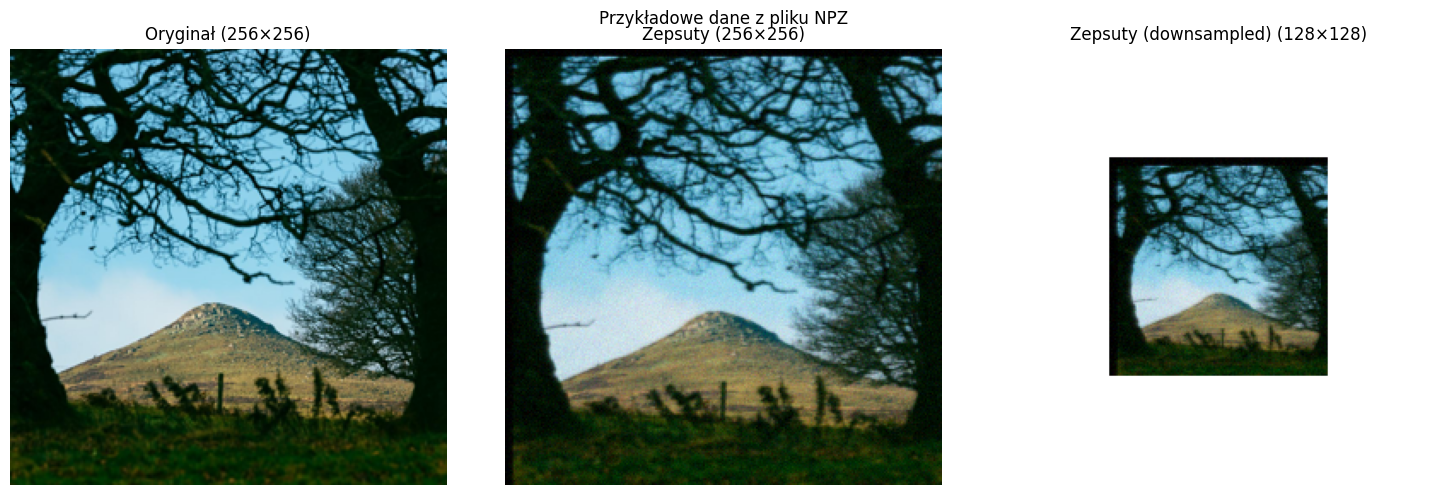

In [ ]:
######################### NIE ZMIENIAJ TEJ KOMÓRKI ##########################

if not FINAL_EVALUATION_MODE:
    download_data()

    # Ścieżka do jednego pliku NPZ z danymi (treningowe + walidacyjne)
    NPZ_PATH = os.path.join('data', 'train_val.npz')

    # Wczytaj zbiory z NPZ
    train_ds, val_ds = setup_data_from_npz(NPZ_PATH) # Zmienne te będą dostępne również podczas finalnej ewaluacji

    if train_ds is not None and val_ds is not None:
        print(f"Ilość obrazów w zbiorze treningowym: {len(train_ds)}")
        print(f"Ilość obrazów w zbiorze walidacyjnym: {len(val_ds)}")

        # Podgląd przykładowych danych
        sample_for_show = val_ds[0]
        plot_results(sample_for_show['image_original'], sample_for_show['image_corrupted'], sample_for_show['image_corrupted_downsampled'], title="Przykładowe dane z pliku NPZ", labels=("Oryginał", "Zepsuty", "Zepsuty (downsampled)"))

## Twoje Rozwiązanie
Poniżej przedstawiamy uproszczone rozwiązania, które służą jako przykład.  Rozwiązania te uzyskują bardzo słabe wyniki, ale demonstrują, jakiego formatu odpowiedzi oczekujemy i mogą posłużyć jako punkt wyjścia do Twojej implementacji.

W tej sekcji należy umieścić Twoje rozwiązanie. Zmiany wprowadzaj wyłącznie tutaj. Do ewaluacji przekazane zostaną funkcje:
- `compute_kernel() -> torch.Tensor`,
- `upsample(image: torch.Tensor) -> torch.Tensor`,
- `compute_kernel_upsampling(kernel_task1: torch.Tensor) -> torch.Tensor`

Możesz w ich kontekście wywoływać dodatkowe funkcje pomocnicze.

Przygotowane wcześniej dane treningowe i walidacyjne są dostępne w zmiennych `train_ds`, `val_ds`.

### Część 1 - Kernel konwolucyjny

In [ ]:
def compute_kernel() -> torch.Tensor:
    """
    Tworzy kernel rozmywający o rozmiarze 9x9.
    """
    kernel = torch.ones(9, 9, device=DEVICE) / 81
    return kernel

### Część 2 - Upsampling

In [ ]:
def upsample(image: torch.Tensor) -> torch.Tensor:
    """
    Prosty upsampling metodą „najbliższego sąsiada” (nearest neighbor)
    do rozmiaru 256x256.

    Idea:
    Każdy piksel z mniejszego obrazu zostaje po prostu powielony kilka razy
    w pionie i poziomie. Dzięki temu obraz robi się większy, ale nie pojawiają
    się nowe szczegóły – widzimy tylko „rozciągnięte” oryginalne piksele.

    Przyjmuje:
        image (torch.Tensor): Obraz w formacie (C, h, w), gdzie:
            - C to liczba kanałów (np. 3 dla RGB),
            - h, w to wysokość i szerokość obrazu (≤ 256).

    Zwraca:
        torch.Tensor: Obraz o kształcie (C, 256, 256) otrzymany przez
        powtórzenie wierszy i kolumn wejścia tyle razy, żeby pokryć
        cały docelowy rozmiar, a następnie przycięcie do dokładnych
        wymiarów 256x256.
    """
    C, h, w = image.shape

    # Docelowe wymiary.
    Ht, Wt = (256, 256)

    # Ile razy musimy powtórzyć wiersze i kolumny, żeby dojść do >= 256.
    rh = max(1, math.ceil(Ht / h))
    rw = max(1, math.ceil(Wt / w))

    # repeat_interleave powiela kolejne wiersze/kolumny odpowiednią liczbę razy.
    y = image.repeat_interleave(rh, dim=1).repeat_interleave(rw, dim=2)

    # Może się zdarzyć, że powtórzeń jest „za dużo” – wtedy przycinamy do 256x256.
    return y[:, :Ht, :Wt]

In [ ]:
def compute_kernel_upsampling(kernel_task1: torch.Tensor) -> torch.Tensor:
    """
    W trakcie ewaluacji kernel z części pierwszej zostanie przekazany
    jako argument. Możesz go użyć lub zignorować.
    """
    return kernel_task1

## Ewaluacja

Uruchomienie poniższej komórki pozwoli sprawdzić, ile punktów zdobyłoby Twoje rozwiązanie na danych walidacyjnych.

Upewnij się przed wysłaniem, że cały notebook wykonuje się od początku do końca bez błędów i bez ingerencji użytkownika po wykonaniu polecenia `Run All`.

MSE na zbiorze walidacyjnym (kernel): 0.0292. Liczba punktów (kernel): 0
MSE na zbiorze walidacyjnym (upsampling): 0.0548. Liczba punktów (upsampling): 0
Estymowana liczba punktów za zadanie: 0


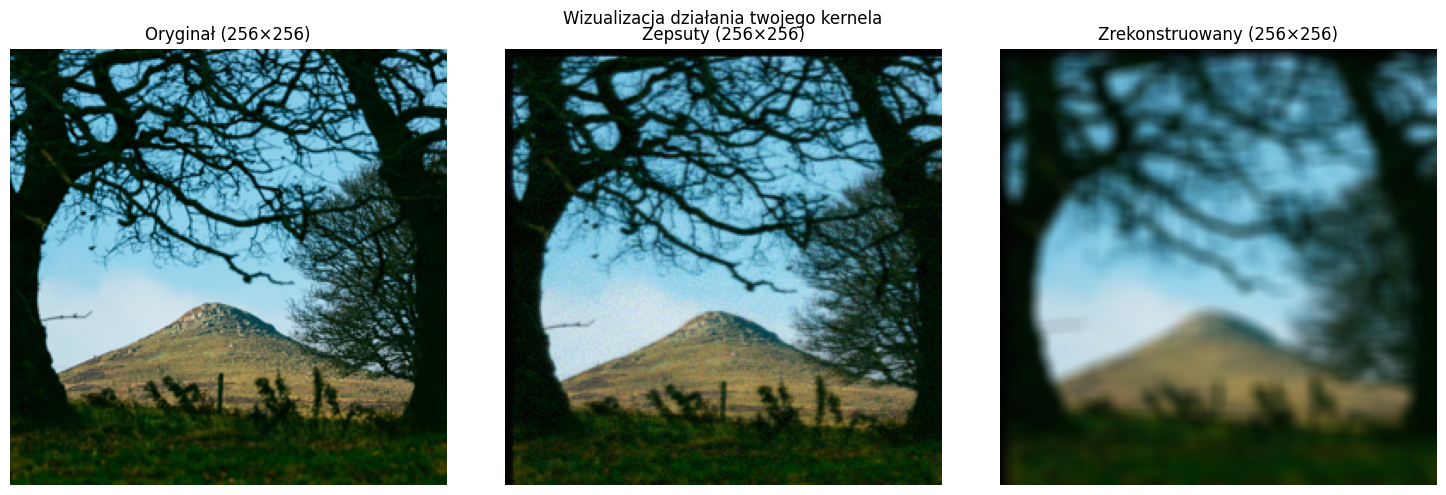

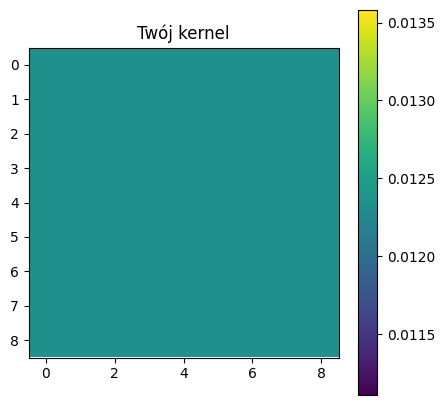

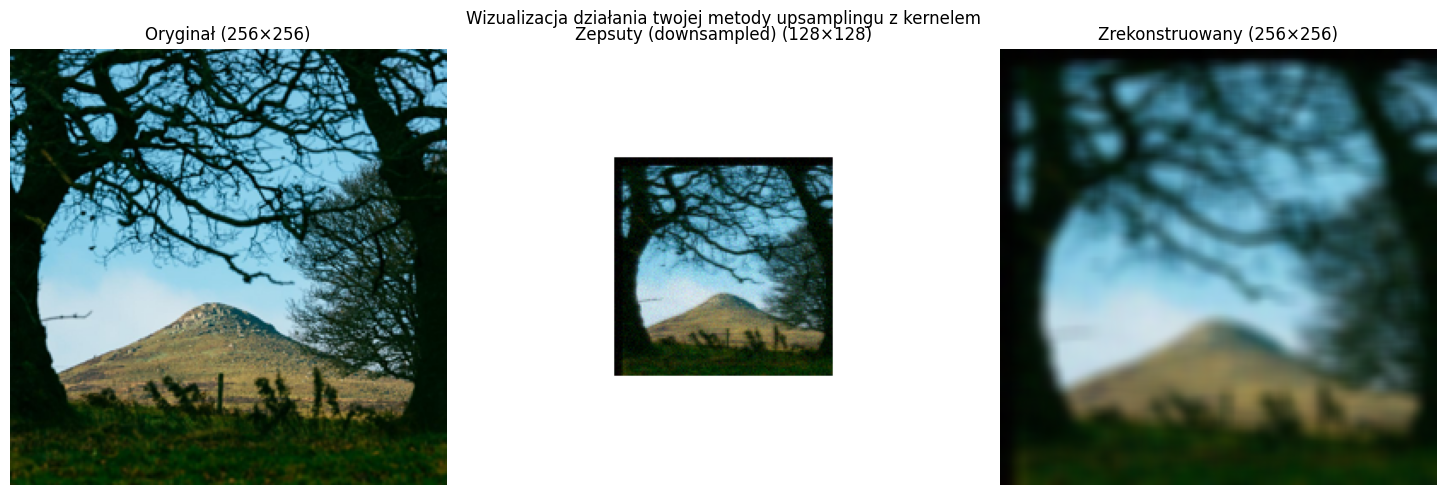

In [ ]:
######################### NIE ZMIENIAJ TEJ KOMÓRKI ##########################

if not FINAL_EVALUATION_MODE:

    # ============== 1) Pierwsza część zadania ==============
    # -- Trening
    your_kernel = compute_kernel()
    # -- Ewaluacja rozwiązania
    your_kernel_mse = evaluate_solution(your_kernel, val_ds)

    # ============== 2) Druga część zadania ==============
    # -- Trening
    your_kernel_upsampling = compute_kernel_upsampling(your_kernel)
    # -- Ewaluacja rozwiązania
    your_upsampling_mse = evaluate_solution(your_kernel_upsampling, val_ds, upsample)

    score, kernel_score, upsampling_score = compute_score(your_kernel_mse, your_upsampling_mse)

    print(f"MSE na zbiorze walidacyjnym (kernel): {your_kernel_mse:.4f}. Liczba punktów (kernel): {kernel_score}")
    print(f"MSE na zbiorze walidacyjnym (upsampling): {your_upsampling_mse:.4f}. Liczba punktów (upsampling): {upsampling_score}")
    print(f"Estymowana liczba punktów za zadanie: {score}")

    # Wizualizacja działania kernela na pojedynczym obrazie walidacyjnym.
    sample_for_show = val_ds[0]
    reconstructed = apply_kernel(sample_for_show['image_corrupted'].to(DEVICE), your_kernel.to(DEVICE))
    plot_results(sample_for_show['image_original'], sample_for_show['image_corrupted'], reconstructed, title="Wizualizacja działania twojego kernela")

    # Podgląd samego kernela (mapa kolorów).
    plt.figure(figsize=(5, 5))
    plt.imshow(your_kernel.cpu().detach().numpy(), cmap='viridis')
    plt.colorbar()
    plt.title("Twój kernel")
    plt.show()

    # Wizualizacja działania upsamplingu z kernelem na pojedynczym obrazie walidacyjnym.
    reconstructed = apply_kernel(upsample(sample_for_show['image_corrupted_downsampled'].to(DEVICE)), your_kernel_upsampling)
    plot_results(sample_for_show['image_original'], sample_for_show['image_corrupted_downsampled'], reconstructed, title="Wizualizacja działania twojej metody upsamplingu z kernelem", labels=("Oryginał", "Zepsuty (downsampled)", "Zrekonstruowany"))

# Modelowe rozwiązanie

Poniższe rozwiązanie przechodzi przez pełny proces dochodzenia do skutecznej rekonstrukcji obrazu, od analizy danych i ograniczeń zadania, przez dobór rozmiaru kernela oraz porównanie kilku wariantów upsamplingu, aż po końcową ewaluację na zbiorze walidacyjnym. Kluczową obserwacją jest liniowy charakter problemu względem wag pojedynczego kernela, co pozwala nie tylko trenować go iteracyjnie, ale również wyznaczać bezpośrednio metodą najmniejszych kwadratów. W części drugiej rozwiązania wykorzystano dodatkowo uczony kernel upsamplingowy, który rekonstruuje obraz powiększony z wersji `128x128`, a następnie przekazuje go do kernela wyostrzającego z części pierwszej.

Rozwiązanie zostało podzielone na następujące kroki:

- **1. Eksploracja danych, ograniczeń i wariantów rozwiązania**
  - **1.1.** Cel i ograniczenia zadania
  - **1.2.** Liczba możliwych rozmiarów kernela
  - **1.3.** Charakter zniekształcenia obrazów
  - **1.4.** Strategiczna obserwacja — problem jest liniowy względem wag kernela
  - **1.5.** Wyznaczenie rozmiaru kernela dla części pierwszej

- **2. Rozwiązanie części 1 — kernel konwolucyjny**
  - **2.1.** Dopasowanie kernela klasyczną konwolucją
  - **2.2.** Dopasowanie kernela iteracyjnie z wykorzystaniem liniowości układu

- **3. Rozwiązanie części 2 — upsampling**
  - **3.1.** Eksploracja metod upsamplingu
    - **3.1.1.** Upsampling nearest neighbor
    - **3.1.2.** Standardowe interpolacje
  - **3.2.** Model kernela upsamplingowego
    - **3.2.1.** Dobór rozmiaru kernela upsamplingowego

- **4. Końcowa architektura rozwiązania**
  - **4.1.** Część 1
  - **4.2.** Część 2

- **5. Wyniki końcowe**

- **6. Wnioski**

- **7. Bonus — podejście alternatywne**
  - **7.1.** Uogólnienie założeń
  - **7.2.** Uzasadnienie matematyczne rozwiązania liniowego
  - **7.3.** Wariant łączony
  - **7.4.** Dwa odrębne kernele w części drugiej

## 1. Eksploracja danych, ograniczeń i wariantów rozwiązania

Pierwszym krokiem powinno zawsze być przeanalizowanie kodu notebooka, ograniczeń i założeń zadania oraz kilku przykładowych próbek ze zbioru treningowego i walidacyjnego. Taka analiza ułatwia rozpoznanie specyfiki problemu, potencjalnych trudności oraz możliwości uproszczenia obliczeń. W tej sekcji zebrano również eksperymenty służące do wyboru rozmiarów obu kerneli, tak aby dalsze części opisu koncentrowały się już na rozwiązaniu końcowym.



### 1.1. Cel i ograniczenia zadania

W części pierwszej oceniany jest jeden kwadratowy kernel konwolucyjny, stosowany identycznie do wszystkich kanałów obrazu. Oznacza to, że dla kernela o rozmiarze `N x N` liczba uczonych wag jest równa:

$N^2$, gdzie $N \in \mathbb{Z}$ oraz $1 \le N \le 10$.

W praktyce redukuje to problem do dopasowania stosunkowo małej liczby parametrów ($N^2 \le 100$), ograniczając przestrzeń, w której porusza się wybrana strategia optymalizacji.

### 1.2. Liczba możliwych rozmiarów kernela

Ze względu na ograniczenie rozmiaru kernela do maksymalnie `10x10` naturalnym pomysłem jest przeprowadzenie krótkiego eksperymentu dla kolejnych rozmiarów `N` z zakresu od 2 do 10. Kernel `1x1` nie wykorzystuje informacji o sąsiedztwie, dlatego nie jest interesujący w kontekście tego zadania. Test pozwala empirycznie ustalić, jak rozmiar jądra wpływa na błąd MSE oraz dla jakiego zakresu warto prowadzić dalsze eksperymenty.

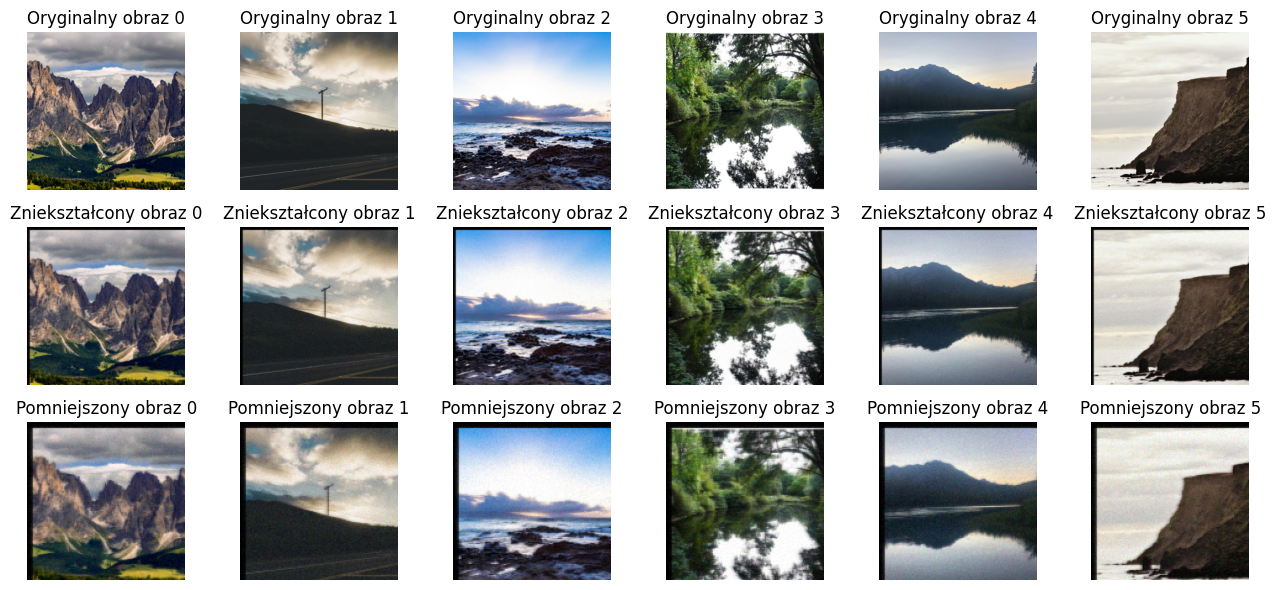

In [ ]:
# Prosta wizualizacja kilku obrazów
fig, axes = plt.subplots(3, 6, figsize=(13, 6))
for i in range(6):
    orig = train_ds[i]['image_original'].permute(1, 2, 0).cpu().numpy()
    corr = train_ds[i]['image_corrupted'].permute(1, 2, 0).cpu().numpy()
    small_corr = train_ds[i]['image_corrupted_downsampled'].permute(1, 2, 0).cpu().numpy()

    axes[0, i].imshow(orig)
    axes[0, i].set_title(f"Oryginalny obraz {i}")
    axes[0, i].axis("off")

    axes[1, i].imshow(corr)
    axes[1, i].set_title(f"Zniekształcony obraz {i}")
    axes[1, i].axis("off")

    # UWAGA obrazy z 3 rzędu są w rzeczywistości dwa razy mniejsze
    axes[2, i].imshow(small_corr)
    axes[2, i].set_title(f"Pomniejszony obraz {i}")
    axes[2, i].axis("off")

plt.tight_layout()
plt.show()

### 1.3. Charakter zniekształcenia obrazów

Przegląd danych ze zbioru treningowego pozwala zaobserwować wspólne cechy zniekształceń.

Widoczne czarne obramowanie występujące tylko na zmodyfikowanych obrazach świadczy o tym, że modyfikacje powstawały sekwencyjnie (szeregowo).

Obrazy pełnego rozmiaru wyglądają tak, jakby zostały poddane jednorodnemu rozmyciu, co sugeruje, że kernel z części pierwszej powinien mieć charakter wyostrzający.

Dodatkowo, `image_corrupted_downsampled` nie wyglądają jak przeskalowane współczynnikiem `0.5` odpowiedniki - znacznie bardziej przypominają rezultat transformacji stratnej, w której utracono część informacji przestrzennej.
To rozróżnienie jest istotne. Celem części drugiej nie jest wyłącznie powiększenie obrazu, ale możliwie dobra rekonstrukcja pełnej reprezentacji z jej uboższej postaci.

### 1.4. Strategiczna obserwacja — problem jest liniowy względem wag kernela

Klasycznym sposobem wyznaczenia takiego jądra jest iteracyjne uczenie wag przez minimalizację funkcji straty. W tym zadaniu można jednak wykorzystać fakt, że konwolucja jednym kernelem jest operacją liniową względem jego współczynników.

Dla każdego położenia w obrazie lokalne okno `N x N` jest spłaszczane do jednego wiersza macierzy `X`, a odpowiadająca mu wartość piksela obrazu oryginalnego trafia do wektora `y`. Wagi kernela zapisujemy jako wektor `k`. Predykcja ma wtedy postać:

$$
\hat{y} = Xk
$$

Nie trzeba przechowywać całej macierzy `X` dla wszystkich obrazów. Wynika to bezpośrednio z liniowości mnożenia macierzy względem dodawania. Jeżeli `x_i` oznacza jeden spłaszczony wektor cech, czyli jedno okno obrazu, a `y_i` odpowiadającą mu wartość docelową, to dla macierzy złożonej z wielu takich wierszy zachodzą zależności:

$$
X^T X = \sum_i x_i x_i^T
$$

$$
X^T y = \sum_i x_i y_i
$$

Innymi słowy: iloczyn `X^T X` można zapisać jako sumę iloczynów zewnętrznych kolejnych wektorów cech, a `X^T y` jako sumę wektorów cech przemnożonych przez odpowiadające im wartości docelowe. Dodawanie można wykonywać w dowolnej kolejności, więc podczas jednego przejścia po zbiorze wystarczy utrzymywać tylko bieżące sumy:

$$
G = X^T X
$$

$$
b = X^T y
$$

Dla kernela `10x10` macierz `G` ma rozmiar `100x100`, a wektor `b` ma 100 elementów. Iteracyjny gradient dla MSE można zapisać jako `Gk - b`.

Powyższa obserwacja stanowi jednocześnie alternatywny sposób rozwiązania zadania, wykorzystując fakt aplikacji pojedynczego kernela. Zamiast wielokrotnie wykonywać pełną konwolucję i propagację wsteczną, można podczas jednego przejścia po zbiorze zgromadzić wektory determinowane przez okno jądra konwolucyjnego i optymalizować wagi w zależności od tej mniejszej reprezentacji.

### 1.5. Wyznaczenie rozmiaru kernela dla części pierwszej

Zgodnie z wcześniejszymi obserwacjami ważnym krokiem jest wybór odpowiedniego rozmiaru okna spośród dostępnych wariantów, a następnie dopasowanie właściwego kernela.

Zakładamy krótkie sesje uczenia, które pozwolą określić, jakie kernele sprawdzają się najlepiej. W zależności od rozległości relacji przestrzennych oraz metody degradacji obrazu zależność rezultatów od rozmiaru może przypominać parabolę (z wyraźnym wyznaczeniem przedziału dobrych kandydatów) lub mieć charakter monotoniczny (rosnący/malejący), faworyzujący małe bądź duże kernele.

In [ ]:
if not FINAL_EVALUATION_MODE:
  EPOCHS = 100
  LR = 0.1
  kernel_size_results = []

  # kolejne wielkości kernela
  for N in range(2, 11):
      kernel = torch.zeros(N, N, device=DEVICE, requires_grad=True)
      kernel.data[N // 2, N // 2] = 1.0
      optimizer = torch.optim.Adam([kernel], lr=LR)

      # pętla uczenia modelu
      for _ in range(EPOCHS):
          optimizer.zero_grad()
          loss = 0.0

          for sample in train_ds:
              corrupted = sample["image_corrupted"].to(DEVICE)
              original = sample["image_original"].to(DEVICE)
              reconstructed = apply_kernel(corrupted, kernel)
              loss = loss + ((reconstructed - original) ** 2).mean()

          loss = loss / len(train_ds)
          loss.backward()
          optimizer.step()

      val_mse = evaluate_solution(kernel.detach(), val_ds)
      kernel_size_results.append((N, float(val_mse)))
      #print(f"{N}x{N}: {val_mse:.6f}")

Wynik eksperymentu dla rozmiarów od `2x2` do `10x10`:


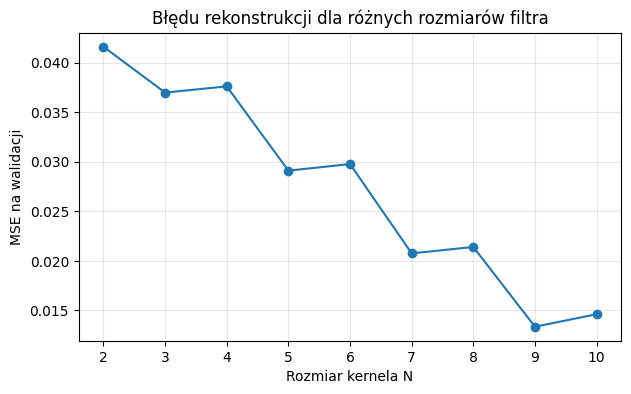

In [ ]:
sizes = [size for size, _ in kernel_size_results]
mses = [mse for _, mse in kernel_size_results]

plt.figure(figsize=(7, 4))
plt.plot(sizes, mses, marker='o')
plt.xticks(sizes)
plt.title('Błędu rekonstrukcji dla różnych rozmiarów filtra')
plt.xlabel('Rozmiar kernela N')
plt.ylabel('MSE na walidacji')
plt.grid(True, alpha=0.3)
plt.show()

Wyniki wykazują wyraźną tendencję skokową: pary rozmiarów `3x3`–`4x4`, `5x5`–`6x6` i `7x7`–`8x8` dają zbliżone rezultaty, natomiast przejście do każdego kolejnego nieparzystego rozmiaru istotnie obniża MSE.

Po 100 szybkich iteracjach per kernel najlepiej wypadają większe okna (`9x9` oraz `10x10`). Ze względu na powtarzający się wzorzec spadek na nieparzystym i lekki wzrost na parzystym korzystniej jest wybrać mniejszy z rozmiarów, biorąc pod uwagę zarówno ograniczenie czasu wykonania zadania, jak i wyniki wstępnego eksperymentu.

## 2. Rozwiązanie części 1 — kernel konwolucyjny


### 2.1. Dopasowanie kernela klasyczną konwolucją

Pierwszym i najbardziej naturalnym podejściem jest wykorzystanie klasycznego podejścia opartego o optymalizacje/ucznenie sieci neuronowej, ponieważ zadanie sprowadza się do optymalizacji funkcji błędu, co wprost zachęca do zastosowania iteracyjnego procesu uczenia.

In [ ]:
N = 9
EPOCHS = 500
LR = 0.1

kernel = torch.zeros(N, N, device=DEVICE, requires_grad=True)
kernel.data[N // 2, N // 2] = 1.0

optimizer = torch.optim.Adam([kernel], lr=LR)

best_kernel = None
best_val_mse = float("inf")
history = []


# realizacja standrowej metody iteracyjnego uczenia sieci neuronowej
for epoch in range(EPOCHS):
    optimizer.zero_grad()

    loss = 0.0
    for sample in train_ds:
        corrupted = sample["image_corrupted"].to(DEVICE)
        original = sample["image_original"].to(DEVICE)

        reconstructed = apply_kernel(corrupted, kernel)
        loss = loss + ((reconstructed - original) ** 2).mean()

    loss = loss / len(train_ds)
    loss.backward()
    optimizer.step()

    val_mse = evaluate_solution(kernel.detach(), val_ds)
    history.append((epoch + 1, float(loss.item()), float(val_mse)))

    if val_mse < best_val_mse:
        best_val_mse = val_mse
        best_kernel = kernel.detach().clone()

    if (epoch + 1) % 50 == 0:
      print(f"Epoka {epoch + 1:03d} | train loss = {loss.item():.6f} | val MSE = {val_mse:.6f}")

kernel_score = compute_score(best_val_mse, 0.0542)[1]
print(f"Najlepsze val MSE dla kernela 9x9: {best_val_mse:.6f}")

Epoka 050 | train loss = 0.021003 | val MSE = 0.018878
Epoka 100 | train loss = 0.011719 | val MSE = 0.013357
Epoka 150 | train loss = 0.010335 | val MSE = 0.011758
Epoka 200 | train loss = 0.009450 | val MSE = 0.010709
Epoka 250 | train loss = 0.008819 | val MSE = 0.009959
Epoka 300 | train loss = 0.008362 | val MSE = 0.009412
Epoka 350 | train loss = 0.008025 | val MSE = 0.009006
Epoka 400 | train loss = 0.007773 | val MSE = 0.008697
Epoka 450 | train loss = 0.007581 | val MSE = 0.008460
Epoka 500 | train loss = 0.007432 | val MSE = 0.008274
Najlepsze val MSE dla kernela 9x9: 0.008274


Takie podejście powinno zapewnić co najmniej 90% możliwych do uzyskania w tej sekcji punktów (~63). Odpowiednio dobrane hiperparametry, takie jak learning rate czy liczba epok, powinny przynieść poprawę wyniku, jednak należy pamiętać o ograniczeniu czasowym.

### 2.2. Dopasowanie kernela iteracyjnie z wykorzystaniem liniowości układu

Alternatywnie można skorzystać z iteracyjnego wariantu gradientu w oparciu o wspomniane reprezentacje konwolucji i liniowości układu.

In [ ]:
def pad_replicate_batch(images: torch.Tensor, pad: int) -> torch.Tensor:
    """Dodaje padding przez replikację brzegów dla całej paczki obrazów.

    Funkcja rozszerza tensor o kształcie `(B, C, H, W)` o `pad` pikseli
    z każdej strony, kopiując skrajne wiersze i kolumny. Dzięki temu
    późniejsza konwolucja zachowuje rozmiar wejściowy i nie wprowadza
    sztucznych zer na granicach obrazu.
    """
    if pad == 0:
        return images

    top = images[:, :, :1, :].expand(-1, -1, pad, -1)
    bottom = images[:, :, -1:, :].expand(-1, -1, pad, -1)
    images = torch.cat([top, images, bottom], dim=2)

    left = images[:, :, :, :1].expand(-1, -1, -1, pad)
    right = images[:, :, :, -1:].expand(-1, -1, -1, pad)
    return torch.cat([left, images, right], dim=3)


def apply_kernel_batch(images: torch.Tensor, kernel: torch.Tensor) -> torch.Tensor:
    """Stosuje ten sam kernel konwolucyjny do wszystkich obrazów.

    Z każdego obrazu tworzone są przesuwane okna `K x K`, a wynik dla
    każdego piksela powstaje jako suma iloczynów elementów okna i wag
    kernela. Operacja działa równolegle dla wymiarów batcha i kanałów.
    """
    B, C, H, W = images.shape
    K = kernel.size(0)
    padded = pad_replicate_batch(images, K // 2)
    sB, sC, sH, sW = padded.stride()
    windows = padded.as_strided(
        size=(B, C, H, W, K, K),
        stride=(sB, sC, sH, sW, sH, sW),
    )
    return (windows * kernel.view(1, 1, 1, 1, K, K)).sum(dim=(-1, -2))


def _fit_kernel_iterative(
    X: torch.Tensor,
    y: torch.Tensor,
    kernel_size: int,
    epochs: int = 750,
    lr: float = 0.05,
    batch_size: int = 12,
) -> torch.Tensor:
    """Dopasowuje kernel konwolucyjny metodą gradientową.

    Funkcja traktuje wagi kernela jako jedyne parametry modelu i uczy je
    przez minimalizację średniego błędu kwadratowego między obrazami po
    filtracji a obrazami docelowymi. Dane są przetwarzane w mniejszych
    paczkach, żeby ograniczyć zużycie pamięci podczas eksperymentów.
    """
    X = X.to(DEVICE)
    y = y.to(DEVICE)
    kernel = torch.zeros(kernel_size, kernel_size, device=DEVICE, requires_grad=True)
    kernel.data[kernel_size // 2, kernel_size // 2] = 1.0
    optimizer = torch.optim.Adam([kernel], lr=lr)

    for _ in range(epochs):
        optimizer.zero_grad()
        loss = 0.0

        for start in range(0, len(X), batch_size):
            reconstructed = apply_kernel_batch(X[start:start + batch_size], kernel)
            loss = loss + ((reconstructed - y[start:start + batch_size]) ** 2).mean()

        loss = loss / ((len(X) + batch_size - 1) // batch_size)
        loss.backward()
        optimizer.step()

    return kernel.detach()


## 3. Rozwiązanie części 2 — upsampling

### 3.1. Eksploracja metod upsamplingu

#### 3.1.1. Upsampling nearest neighbor

Punktem startowym był upsampling typu nearest neighbor. Metoda ta jest prosta, ale ma istotną wadę: nie rekonstruuje nowych wartości, tylko kopiuje istniejące piksele. W konsekwencji:

- powiększony obraz ma strukturę blokową,
- wiele sąsiednich wartości jest identycznych,
- kernel z części pierwszej nie otrzymuje dobrej bazy do wyostrzania,
- wyostrzanie obrazu o dużej liczbie identycznych sąsiedztw jest mało skuteczne.

Wynik takiego podejścia dla wyznaczonego w części 1 kernela wyniesie około `0.04` MSE, nie gwarantując wysokiej oceny zadania.

#### 3.1.2. Standardowe interpolacje

Naturalnym krokiem jest przetestowanie rekonstrukcji opartych na sąsiedztwie:

**Bilinear** wykorzystuje cztery najbliższe piksele i interpolację liniową w dwóch osiach. (https://pl.wikipedia.org/wiki/Interpolacja_dwuliniowa)

**Bicubic** wykorzystuje otoczenie `4x4` oraz sześcienną funkcję wagową, dzięki czemu może tworzyć gładsze przejścia, ale może również wzmacniać artefakty obecne w danych. (https://en.wikipedia.org/wiki/Bicubic_interpolation)

Ze względu na zakaz korzystania z `torch.nn` interpolacje zostały zaimplementowane ręcznie.

In [ ]:
def bilinear_round_scale(image: torch.Tensor) -> torch.Tensor:
    """Skaluje obraz do wymiarów 256x256 używając dwuliniowej (bilinear) interpolacji.

    Funkcja mapuje piksele docelowe na obraz wejściowy bez wyśrodkowania
    krawędzi (corner-aligned), pobiera 4 najbliższych sąsiadów i wykonuje
    ważone uśrednianie wzdłuż obu osi.

    Parameters
    ----------
    image : torch.Tensor
        Tensor wejściowego obrazu o kształcie (C, H, W).

    Returns
    -------
    torch.Tensor
        Przeskalowany obraz o kształcie (C, 256, 256) i tym samym typie danych.

    """
    channels, height, width = image.shape
    target_height, target_width = 256, 256

    # Skala przejścia z przestrzeni wyjściowej do wejściowej
    scale_y = height / target_height
    scale_x = width / target_width

    # Wyznaczenie ciągłych (zmiennopozycyjnych) współrzędnych w obrazie źródłowym
    y_grid = (
        torch.arange(target_height, dtype=image.dtype, device=image.device)
        * scale_y
    ).clamp(0, height - 1)
    x_grid = (
        torch.arange(target_width, dtype=image.dtype, device=image.device)
        * scale_x
    ).clamp(0, width - 1)

    # Indeksy lewego/górnego sąsiada (podłoga ze współrzędnych)
    y_top = y_grid.floor().long()
    x_left = x_grid.floor().long()

    # Indeksy prawego/dolnego sąsiada (ograniczone do granic obrazu)
    y_bottom = (y_top + 1).clamp(max=height - 1)
    x_right = (x_left + 1).clamp(max=width - 1)

    # Odległości ułamkowe od lewego i górnego sąsiada (wagi)
    delta_y = (y_grid - y_top).view(target_height, 1)
    delta_x = (x_grid - x_left).view(1, target_width)

    # Interpolacja wzdłuż osi X dla górnej i dolnej krawędzi
    top_row = image[:, y_top[:, None], x_left[None, :]] * (
        1 - delta_x
    ) + image[:, y_top[:, None], x_right[None, :]] * delta_x
    bottom_row = image[:, y_bottom[:, None], x_left[None, :]] * (
        1 - delta_x
    ) + image[:, y_bottom[:, None], x_right[None, :]] * delta_x

    # Finalna interpolacja wzdłuż osi Y
    return top_row * (1 - delta_y) + bottom_row * delta_y

def bicubic(image: torch.Tensor) -> torch.Tensor:
    """Skaluje obraz do wymiarów 256x256 za pomocą interpolacji dwusześciennej.
    Pobiera otoczenie 4x4 wokół każdego punktu wyjściowego.

    Parameters
    ----------
    image : torch.Tensor
        Tensor wejściowego obrazu o kształcie (C, H, W).

    Returns
    -------
    torch.Tensor
        Przeskalowany obraz o kształcie (C, 256, 256) i tym samym typie danych.

    """
    channels, height, width = image.shape
    target_height, target_width = 256, 256

    # Wyznaczenie ciągłych współrzędnych z uwzględnieniem wyśrodkowania pikseli
    y_grid = (
        torch.arange(target_height, dtype=image.dtype, device=image.device)
        + 0.5
    ) * height / target_height - 0.5
    x_grid = (
        torch.arange(target_width, dtype=image.dtype, device=image.device)
        + 0.5
    ) * width / target_width - 0.5

    # Punkt odniesienia
    y_base = y_grid.floor().long()
    x_base = x_grid.floor().long()

    output = torch.zeros(
        channels,
        target_height,
        target_width,
        dtype=image.dtype,
        device=image.device,
    )

    # Parametr wykorzystywany w metodzie bicubic
    cubic_param_a = -0.75

    # Sumowanie po otoczeniu 4x4 wokół każdego punktu docelowego (-1, 0, 1, 2)
    for offset_y in range(-1, 3):
        y_neighbor = (y_base + offset_y).clamp(0, height - 1)
        dist_y = (y_grid - y_base - offset_y).abs()

        # Obliczenie wag wielomianowych dla osi Y (Wielomiany Keysa)
        y_weight = torch.where(
            dist_y <= 1,
            (cubic_param_a + 2) * dist_y**3
            - (cubic_param_a + 3) * dist_y**2
            + 1,
            torch.where(
                dist_y < 2,
                cubic_param_a * dist_y**3
                - 5 * cubic_param_a * dist_y**2
                + 8 * cubic_param_a * dist_y
                - 4 * cubic_param_a,
                0,
            ),
        ).view(target_height, 1)

        for offset_x in range(-1, 3):
            x_neighbor = (x_base + offset_x).clamp(0, width - 1)
            dist_x = (x_grid - x_base - offset_x).abs()

            # Obliczenie wag wielomianowych dla osi X
            x_weight = torch.where(
                dist_x <= 1,
                (cubic_param_a + 2) * dist_x**3
                - (cubic_param_a + 3) * dist_x**2
                + 1,
                torch.where(
                    dist_x < 2,
                    cubic_param_a * dist_x**3
                    - 5 * cubic_param_a * dist_x**2
                    + 8 * cubic_param_a * dist_x
                    - 4 * cubic_param_a,
                    0,
                ),
            ).view(1, target_width)

            # Wyznaczenie nowego obrazu wykorzystując kombinację wag
            output += (
                image[:, y_neighbor[:, None], x_neighbor[None, :]]
                * y_weight
                * x_weight
            )

    return output

Wyniki po zastosowaniu kernela `9x9` z części pierwszej:

| Metoda | MSE |
|---|---:|
| nearest neighbor | 0.041620 |
| bilinear | **0.036393** |
| bicubic | 0.040749 |

Z opisanych interpolacji najlepszy wynik osiągnęła metoda bilinear - był wyraźnie lepszy niż nearest neighbor, ale nadal pozostaje przestrzeń do poprawy. Kluczowe jest to, że standardowe interpolacje nie wykorzystują informacji o specyfice transformacji obecnej w zbiorze treningowym.

### 3.2. Model kernela upsamplingowego

Aby wykorzystać wiedzę zawartą w danych, można spróbować utworzyć jądro uczone specjalnie do odwracania procesu redukcji rozdzielczości.

Obraz o rozmiarze `128x128` jest mapowany na siatkę `256x256` w taki sposób, że wartości wejściowe trafiają na co drugą pozycję, a pozostałe miejsca są wypełniane zerami. Powstaje w ten sposób siatka, której puste pola odpowiadają pikselom wymagającym rekonstrukcji.

In [ ]:
def zero_insert_2x(image: torch.Tensor) -> torch.Tensor:
    C, h, w = image.shape
    out = torch.zeros(C, h * 2, w * 2, dtype=image.dtype, device=image.device)
    out[:, 0::2, 0::2] = image
    return out


Na tak przygotowany obraz nakładany jest kwadratowy kernel rekonstrukcyjny o wymiarach `N x N`.

Kernel upsamplingowy może zostać dopasowany analogicznie do kernela z części pierwszej. Macierz cech powstaje z okien obrazu po operacji `zero-insert`, a wartościami docelowymi są piksele obrazu oryginalnego. W końcowym kroku wynik przechodzi następnie przez kernel wyostrzający `9x9`.

#### 3.2.1. Dobór rozmiaru kernela upsamplingowego

Nieparzyste rozmiary okna mają naturalnie określony środek i dobrze współpracują z konwencją `zero-insert`.

In [ ]:
def _fit_upsample_kernel_iterative(
    X: torch.Tensor,
    y: torch.Tensor,
    kernel_size: int,
    epochs: int = 500,
    lr: float = 0.05,
    batch_size: int = 12,
) -> torch.Tensor:
    """Uczy kernel rekonstruujący obraz po operacji `zero-insert 2x`.

    Obrazy wejściowe są najpierw rozszerzane do dwukrotnie większej
    siatki przez wstawienie zer między znane piksele. Następnie uczony
    jest jeden kernel, który z takiej rzadkiej reprezentacji odtwarza
    możliwie bliski obraz docelowy, minimalizując MSE.
    """
    X = X.to(DEVICE)
    y = y.to(DEVICE)

    B, C, H, W = X.shape

    upsampled = torch.zeros(
        B,
        C,
        H * 2,
        W * 2,
        dtype=X.dtype,
        device=DEVICE,
    )
    upsampled[:, :, 0::2, 0::2] = X

    kernel = torch.zeros(
        kernel_size,
        kernel_size,
        device=DEVICE,
        requires_grad=True,
    )
    kernel.data[kernel_size // 2, kernel_size // 2] = 1.0

    optimizer = torch.optim.Adam([kernel], lr=lr)

    for _ in range(epochs):
        optimizer.zero_grad()
        loss = 0.0
        samples = 0

        for start in range(0, len(upsampled), batch_size):
            batch = upsampled[start:start + batch_size]
            target = y[start:start + batch_size]

            reconstructed = apply_kernel_batch(batch, kernel)

            current_batch_size = len(batch)

            loss = loss + (
                (reconstructed - target) ** 2
            ).mean() * current_batch_size

            samples += current_batch_size

        loss = loss / samples

        loss.backward()
        optimizer.step()

    return kernel.detach()


In [ ]:
#------Eksperyment-------#
upsampling_results = []

X_train = torch.stack([
    sample["image_corrupted_downsampled"]
    for sample in train_ds
])

y_train = torch.stack([
    sample["image_original"]
    for sample in train_ds
])

for kernel_size in (3, 5, 7, 9):
    kernel_2 = _fit_upsample_kernel_iterative(
        X_train,
        y_train,
        kernel_size=kernel_size,
        epochs=100,
    ).to(DEVICE)

    mse = 0.0

    with torch.no_grad():
        for sample in val_ds:
            image = sample["image_corrupted_downsampled"].to(DEVICE)

            reconstructed = apply_kernel(
                zero_insert_2x(image),
                kernel_2,
            ).clamp(0.0, 1.0)

            mse += (
                (
                    reconstructed
                    - sample["image_original"].to(DEVICE)
                ) ** 2
            ).mean().item()

    upsampling_results.append(
        (kernel_size, mse / len(val_ds))
    )

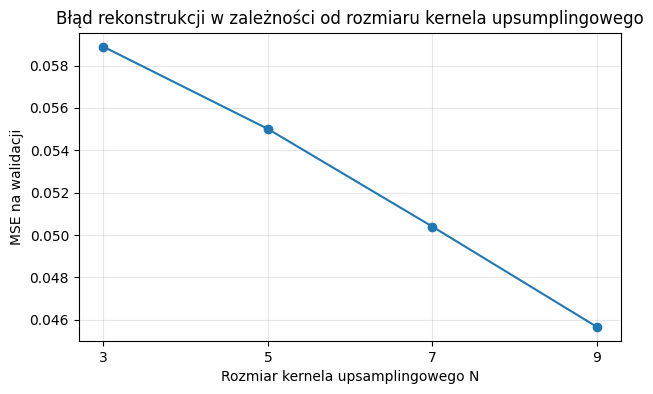

In [ ]:
sizes = [size for size, _ in upsampling_results]
mses = [mse for _, mse in upsampling_results]

plt.figure(figsize=(7, 4))
plt.plot(sizes, mses, marker='o')
plt.xticks(sizes)
plt.title("Błąd rekonstrukcji w zależności od rozmiaru kernela upsumplingowego")
plt.xlabel('Rozmiar kernela upsamplingowego N')
plt.ylabel('MSE na walidacji')
plt.grid(True, alpha=0.3)
plt.show()


Na walidacji otrzymano:

| Kernel upsamplingowy | MSE |
|---|---:|
| `3x3` | 0.058887 |
| `5x5` | 0.055009 |
| `7x7` | 0.050399 |
| `9x9` | **0.045668** |

Przy ocenie czystej rekonstrukcji, bez dodatkowego kernela z części pierwszej, najlepszy wynik dawał największy testowany kernel `9x9`. Warto mieć jednak na uwadze, że za ostateczny rezultat odpowiada w tymm układzie dopiero kombinacja `kernel_2` -> `kernel_1`. Istotne są też względy wydajnościowe; jest to drugi z wyznaczanych kerneli, więc czasu na jego wyliczenie może być relatywnie mniej. Opierając się na tym, pierwszy eksperyment zostanie przeprowadzony dla jądra 7x7.

## 4. Końcowa architektura rozwiązania

Niezależnie od przyjętych wcześniej strategii uczenia `kernel_1` i `kernel_2` w rozwiązaniu końcowym:

- kernel upsamplingowy odpowiada za rekonstrukcję brakujących informacji przestrzennych,
- kernel z części pierwszej odpowiada za końcową korektę i wyostrzanie.



### 4.1. Część 1

Polega na dopasowaniu jednego kernela `9x9`.

In [ ]:
# wyznaczanie kernela zgodnie z interfejsem zadania
def compute_kernel() -> torch.Tensor:
  kernel_1 = _fit_kernel_iterative(
    torch.stack([sample["image_corrupted"] for sample in train_ds]),
    torch.stack([sample["image_original"] for sample in train_ds]),
    kernel_size=9,
  )
  return kernel_1

# zastosowanie go bezpośrednio do obrazu `image_corrupted`.
reconstructed = apply_kernel(
  val_ds[0]["image_corrupted"].to(DEVICE),
  compute_kernel().to(DEVICE),
)

### 4.2. Część 2

Polega na następujących krokach:
1. `image_corrupted_downsampled` jest rozszerzany do siatki `256x256` metodą `zero-insert 2x`,
2. Jeden uczony kernel `7x7` rekonstruuje brakujące wartości,
3. Wynik przechodzi przez kernel `9x9` z części pierwszej.


In [ ]:
kernel_2 = _fit_upsample_kernel_iterative(
    torch.stack([sample["image_corrupted_downsampled"] for sample in train_ds]),
    torch.stack([sample["image_corrupted"] for sample in train_ds]),
    kernel_size=7,
    epochs = 200
).to(DEVICE)

In [ ]:
#funkcja upsample zgodna z przyjętą strategią
def upsample(image: torch.Tensor) -> torch.Tensor:
    z = zero_insert_2x(image)
    return apply_kernel(z, kernel_2).clamp(0.0, 1.0)


## 5. Wyniki końcowe



In [ ]:
######################### NIE ZMIENIAJ TEJ KOMÓRKI ##########################

if not FINAL_EVALUATION_MODE:

    # ============== 1) Pierwsza część zadania ==============
    # -- Trening
    your_kernel = compute_kernel()
    # -- Ewaluacja rozwiązania
    your_kernel_mse = evaluate_solution(your_kernel, val_ds)

    # ============== 2) Druga część zadania ==============
    # -- Policzony kernel_2
    your_kernel_upsampling = your_kernel
    # -- Ewaluacja rozwiązania
    your_upsampling_mse = evaluate_solution(your_kernel_upsampling, val_ds, upsample)

    score, kernel_score, upsampling_score = compute_score(your_kernel_mse, your_upsampling_mse)

    print(f"MSE na zbiorze walidacyjnym (kernel): {your_kernel_mse:.4f}. Liczba punktów (kernel): {kernel_score}")
    print(f"MSE na zbiorze walidacyjnym (upsampling): {your_upsampling_mse:.4f}. Liczba punktów (upsampling): {upsampling_score}")
    print(f"Estymowana liczba punktów za zadanie: {score}")

MSE na zbiorze walidacyjnym (kernel): 0.0078. Liczba punktów (kernel): 70
MSE na zbiorze walidacyjnym (upsampling): 0.0293. Liczba punktów (upsampling): 30
Estymowana liczba punktów za zadanie: 100


Po uruchomieniu pełnej walidacji uzyskano:

- `MSE kernel = 0.0078`,
- `MSE upsampling = 0.0293`,
- `70/70` punktów za część pierwszą,
- `30/30` punktów za część drugą,
- `100/100` punktów łącznie na dostarczonym zbiorze walidacyjnym.

## 6. Wnioski

Przebieg eksperymentu pokazuje kilka istotnych rzeczy:

- w części pierwszej kluczowy okazał się odpowiednio duży kernel `9x9`,
- samo przejście z nearest neighbor do interpolacji bilinear istotnie poprawiało wynik,
- najlepsze rezultaty dało wykorzystanie informacji zawartej w zbiorze danych do nauczenia oddzielnego kernela rekonstrukcyjnego dla upsamplingu,
- prosty model z jednym uczonym kernelem `NxN` dla rekonstrukcji i jednym kernelem `9x9` dla wyostrzania spełniał założenia zadania i osiągnął maksymalną punktację na walidacji.

## 7. Bonus - podejście alternatywne

### 7.1. Uogólnienie założeń

W przypadku tego zadania dopasowanie okna upsamplingu do `image_original` dawało zbliżony wynik jak w przypadku przyrównania do "zamglonego" wariantu, więc ostatecznie wybór danych referencyjnych do upsamplingu nie wpływa na rozwiązania najlepsze, niemniej jednak może mieć wpływ (kilkupunktowy) na końcowy rezultat.

### 7.2. Uzasadnienie matematyczne rozwiązania liniowego

Możliwość wyznaczenia pojedynczego filtru dla każdej z sekcji, czyli brak typowej nieliniowości, często występującej w sieciach konwolucyjnych, pozwala na przyspieszenie iteracyjnego procesu poprzez zmianę reprezentacji zbioru wejściowego. Obserwację można rozszerzyć - powstały układ równań liniowych można rozwiązać analitycznie za pomocą regresji liniowej i metody najmniejszych kwadratów

Problem można więc potraktować jako zestaw równań liniowych i wyznaczyć optymalny zestaw wag minimalizujący MSE całego zbioru.
Po oznaczeniu $$G = X^T X$$ $$b = X^T y$$ układ ma postać: $$Gk = b$$ <br /> Tak wyznaczane jądro nie wymaga wieloepokowego uczenia, co pozwala wykonać zadanie zdecydowanie szybciej oraz znaleźć globalne minimum funkcji kwadratowej dla danego rozmiaru kernela.

Uczenie kernela rekonstrukcyjnego ma postać regresji liniowej:

In [ ]:
def fit_kernel_linsolve(X: torch.Tensor, y: torch.Tensor, N: int) -> torch.Tensor:
    """Wyznacza kernel jako rozwiązanie równań normalnych.

    Funkcja tworzy dla kolejnych obrazów lokalne okna konwolucyjne i akumuluje
    składniki `X^T X` oraz `X^T y`, po czym rozwiązuje mały układ liniowy
    względem `N**2` współczynników kernela.
    """
    n = N**2
    xtx = torch.zeros(n, n, dtype=torch.float64)
    xty = torch.zeros(n, dtype=torch.float64)

    for image, target in zip(X, y):
        padded = _pad_replicate(image, N // 2)
        C, H, W = image.shape
        sC, sH, sW = padded.stride()
        windows = padded.as_strided((C, H, W, N, N), (sC, sH, sW, sH, sW))
        windows = windows.reshape(-1, n).to(torch.float64)
        target = target.reshape(-1).to(torch.float64)
        xtx += windows.T @ windows
        xty += windows.T @ target

    return torch.linalg.solve(
        xtx + 1e-5 * torch.eye(n, dtype=torch.float64),
        xty,
    ).reshape(N, N).to(DEVICE, dtype=torch.float32)


`kernel_2` można wyznaczyć w taki sam sposób. Zarówno `kernel_1` jak i `kernel_2` przyjmują idealne wagi dla odpowiadającego im problemu, uzyskują optimum do którego dążą metody opisane w rozwiązaniu.

### 7.3. Wariant łączony
`kernel_2` optymalizuje proces upsamplingu przed zastosowaniem `kernel_1`, który w tym ujęciu jest stały. Oznacza to, że dla bardziej skompresowanej architektury, możliwe jest uczenie `kernel_2` poprzez propagację błędu procesu, dla którego predykcja to `kernel_2` -> `kernel_1` zestawione z image_original. Pozwala to uczyć jeden z kerneli, od razu biorąc pod uwagę wpływ drugiego lub - w zaawansowanym wariancie - uczyć oba kernele jednocześnie. Jednakże, biorąc pod uwagę konstrukcję zadania i kryteria oceny, może być to niepotrzebne ryzyko wydajnościowe i jakościowe względem wyżej wymienionych metod rozwiązania.

### 7.4. Dwa odrębne kernele w części drugiej

Zadanie dopuszcza wyznaczanie wszystkich kerneli dla obu części zadania oddzielnie. Można więc potraktować część drugą jako osobny dwuetapowy problem, w którym `upsample` najpierw wykonuje rekonstrukcję obrazu do rozmiaru `256x256`, a następnie `compute_kernel_upsampling` zwraca drugi, niezależnie wyznaczony kernel dla obrazu już powiększonego.

W takim wariancie nadal liczone są dwa kernele, ale ich role są rozdzielone inaczej niż w wariancie łączonym. Pierwszy kernel, z części pierwszej, pozostaje rozwiązaniem problemu pełnowymiarowego `image_corrupted -> image_original`. Drugi kernel jest natomiast dopasowywany specjalnie do reprezentacji powstałej po wybranej metodzie upsamplingu. Nie musi być zatem kopią `kernel_1`, ponieważ pracuje na innym typie wejścia i może kompensować artefakty wprowadzone przez sam etap powiększania.

Pozwala to na realizację następującego scenariusza:
najpierw wybieramy bazowy sposób zwiększenia rozdzielczości, np. `zero-insert`, nearest neighbor albo interpolację, a potem uczymy kernel końcowy na parach: wynik upsamplingu jako wejście oraz obraz referencyjny jako cel. Jest to podejście pośrednie między prostym, ponownym użyciem `kernel_1` a pełnym uczeniem współpracujących filtrów. Zachowuje czytelny podział na etapy, a jednocześnie pozwala drugiemu kernelowi lepiej dopasować się do błędów charakterystycznych dla części drugiej. Natomiast ponownie należy brać pod uwagę to, że jakość zależy od dwóch decyzji naraz: wyboru metody upsamplingu oraz sposobu dopasowania końcowego kernela.